# GPU-Based Batch Image Processing Using CUDA
This notebook compiles and runs a CUDA C++ program in a GPU-enabled Google Colab runtime. It generates 200 synthetic RGB images, converts them to grayscale with a CUDA kernel, saves outputs, and records real execution timings.

**Important:** In Colab, choose **Runtime → Change runtime type → T4 GPU** (or another available GPU), then run the cells in order. GPU availability depends on your account and current capacity.

In [1]:
!nvidia-smi
!nvcc --version

Mon Nov 16 04:28:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Create the CUDA source code

In [2]:
%%writefile batch_grayscale.cu
#include <cuda_runtime.h>
#include <algorithm>
#include <chrono>
#include <filesystem>
#include <fstream>
#include <iostream>
#include <string>
#include <vector>

namespace fs = std::filesystem;

#define CUDA_CHECK(call) do { \
  cudaError_t err = (call); \
  if (err != cudaSuccess) { \
    std::cerr << "CUDA error: " << cudaGetErrorString(err) << "\n"; \
    return 1; \
  } \
} while (0)

struct Image {
  int width = 0, height = 0;
  std::vector<unsigned char> pixels;
  fs::path path;
};

bool ReadPpm(const fs::path& path, Image* image) {
  std::ifstream in(path, std::ios::binary);
  if (!in) return false;
  std::string magic;
  int max_value = 0;
  in >> magic >> image->width >> image->height >> max_value;
  in.get();
  if (magic != "P6" || max_value != 255 ||
      image->width <= 0 || image->height <= 0) return false;
  size_t bytes = static_cast<size_t>(image->width) * image->height * 3;
  image->pixels.resize(bytes);
  in.read(reinterpret_cast<char*>(image->pixels.data()), bytes);
  image->path = path;
  return static_cast<bool>(in);
}

bool WritePgm(const fs::path& path, int w, int h,
              const std::vector<unsigned char>& pixels) {
  std::ofstream out(path, std::ios::binary);
  if (!out) return false;
  out << "P5\n" << w << " " << h << "\n255\n";
  out.write(reinterpret_cast<const char*>(pixels.data()), pixels.size());
  return static_cast<bool>(out);
}

__global__ void RgbToGray(const unsigned char* rgb,
                          unsigned char* gray, int count) {
  int i = blockIdx.x * blockDim.x + threadIdx.x;
  if (i < count) {
    int r = rgb[3 * i], g = rgb[3 * i + 1], b = rgb[3 * i + 2];
    gray[i] = static_cast<unsigned char>((77 * r + 150 * g + 29 * b) >> 8);
  }
}

int main(int argc, char** argv) {
  fs::path input_dir = argc > 1 ? argv[1] : "input";
  fs::path output_dir = argc > 2 ? argv[2] : "output";
  fs::create_directories(output_dir);

  std::vector<fs::path> files;
  for (const auto& entry : fs::directory_iterator(input_dir))
    if (entry.is_regular_file() && entry.path().extension() == ".ppm")
      files.push_back(entry.path());
  std::sort(files.begin(), files.end());
  if (files.empty()) {
    std::cerr << "No PPM images found. Generate the dataset first.\n";
    return 1;
  }

  double cpu_total_ms = 0.0, gpu_total_ms = 0.0;
  int processed = 0;

  for (const auto& file : files) {
    Image image;
    if (!ReadPpm(file, &image)) continue;
    int count = image.width * image.height;
    size_t input_bytes = image.pixels.size();
    size_t output_bytes = static_cast<size_t>(count);
    std::vector<unsigned char> gray(output_bytes);

    auto cpu_start = std::chrono::steady_clock::now();
    for (int i = 0; i < count; ++i) {
      int r = image.pixels[3*i], g = image.pixels[3*i+1], b = image.pixels[3*i+2];
      gray[i] = static_cast<unsigned char>((77*r + 150*g + 29*b) >> 8);
    }
    auto cpu_end = std::chrono::steady_clock::now();
    cpu_total_ms += std::chrono::duration<double, std::milli>(cpu_end-cpu_start).count();

    unsigned char *d_rgb = nullptr, *d_gray = nullptr;
    CUDA_CHECK(cudaMalloc(&d_rgb, input_bytes));
    CUDA_CHECK(cudaMalloc(&d_gray, output_bytes));
    cudaEvent_t start, stop;
    CUDA_CHECK(cudaEventCreate(&start));
    CUDA_CHECK(cudaEventCreate(&stop));
    CUDA_CHECK(cudaEventRecord(start));
    CUDA_CHECK(cudaMemcpy(d_rgb, image.pixels.data(), input_bytes, cudaMemcpyHostToDevice));
    int threads = 256, blocks = (count + threads - 1) / threads;
    RgbToGray<<<blocks, threads>>>(d_rgb, d_gray, count);
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaMemcpy(gray.data(), d_gray, output_bytes, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaEventRecord(stop));
    CUDA_CHECK(cudaEventSynchronize(stop));
    float elapsed = 0.0f;
    CUDA_CHECK(cudaEventElapsedTime(&elapsed, start, stop));
    gpu_total_ms += elapsed;
    CUDA_CHECK(cudaEventDestroy(start));
    CUDA_CHECK(cudaEventDestroy(stop));
    CUDA_CHECK(cudaFree(d_rgb));
    CUDA_CHECK(cudaFree(d_gray));

    if (!WritePgm(output_dir / (file.stem().string() + "_gray.pgm"),
                  image.width, image.height, gray)) return 1;
    ++processed;
  }

  int device_count = 0;
  CUDA_CHECK(cudaGetDeviceCount(&device_count));
  std::cout << "CUDA devices detected: " << device_count << "\n";
  std::cout << "Images processed: " << processed << "\n";
  std::cout << "CPU processing time (sum): " << cpu_total_ms << " ms\n";
  std::cout << "GPU pipeline time (sum, includes transfers): " << gpu_total_ms << " ms\n";
  std::cout << "Output directory: " << output_dir << "\n";
  return 0;
}


Writing batch_grayscale.cu


## 2. Generate 200 sample RGB images

In [3]:
from pathlib import Path

p = Path("batch_grayscale.cu")
s = p.read_text()

s = s.replace(r'\\n', r'\n')
s = s.replace(
    'cudaMalloc(&d_rgb,',
    'cudaMalloc(reinterpret_cast<void**>(&d_rgb),'
)
s = s.replace(
    'cudaMalloc(&d_gray,',
    'cudaMalloc(reinterpret_cast<void**>(&d_gray),'
)

p.write_text(s)
print("CUDA source corrections applied.")

CUDA source corrections applied.


In [4]:
import math, random
from pathlib import Path

input_dir = Path("input")
input_dir.mkdir(exist_ok=True)
count, width, height = 200, 256, 256

for image_id in range(count):
    rng = random.Random(image_id)
    pixels = bytearray()
    for y in range(height):
        for x in range(width):
            wave = int(127.5 + 127.5 * math.sin((x + image_id * 7) * 0.035)
                      * math.cos((y + image_id * 3) * 0.027))
            pixels.extend(((wave + rng.randrange(32)) % 256,
                           (x + image_id * 11) % 256,
                           (y * 2 + image_id * 5) % 256))
    with (input_dir / f"image_{image_id:04d}.ppm").open("wb") as f:
        f.write(f"P6\n{width} {height}\n255\n".encode())
        f.write(pixels)

print(f"Generated {count} images of size {width}x{height}.")


Generated 200 images of size 256x256.


## 3. Compile and execute the CUDA program

In [5]:
!nvcc -O2 -std=c++17 batch_grayscale.cu -o batch_grayscale
!mkdir -p output artifacts
!./batch_grayscale input output 2>&1 | tee artifacts/run_log.txt

CUDA devices detected: 1
Images processed: 200
CPU processing time (sum): 27.2957 ms
GPU pipeline time (sum, includes transfers): 23.2442 ms
Output directory: "output"


## 4. Check output images and execution evidence

In [6]:
from pathlib import Path
outputs = sorted(Path('output').glob('*.pgm'))
print('Output images:', len(outputs))
print('First five:', [p.name for p in outputs[:5]])
assert len(outputs) == 200, 'Expected 200 processed output images.'
print('Output verification passed.')

Output images: 200
First five: ['image_0000_gray.pgm', 'image_0001_gray.pgm', 'image_0002_gray.pgm', 'image_0003_gray.pgm', 'image_0004_gray.pgm']
Output verification passed.


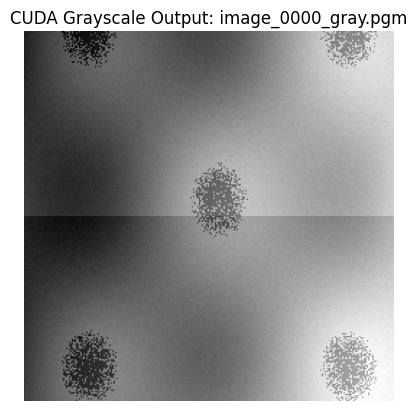

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
sample = Image.open(outputs[0])
plt.imshow(sample, cmap='gray')
plt.title('CUDA Grayscale Output: ' + outputs[0].name)
plt.axis('off');
plt.show()

In [8]:
!zip -qr cuda_execution_evidence.zip artifacts output
print('Created cuda_execution_evidence.zip. Download it from the Colab Files panel.')

Created cuda_execution_evidence.zip. Download it from the Colab Files panel.
